# 01 — Data Preprocessing & Augmentation Pipeline QA

**Phase 2.7 | SENSE Project**

Visualizes raw vs. stereo-augmented image pairs and pixel intensity distributions
before and after ImageNet normalization and on-the-fly augmentation.


In [1]:
import os
PROJECT_ROOT = r'C:\Users\Tamim Syeedur Rahman\All Codes\sense-project'
os.chdir(PROJECT_ROOT)
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

PROCESSED_DIR = Path('data/processed')
print('Project Root:', PROJECT_ROOT)


Project Root: C:\Users\Tamim Syeedur Rahman\All Codes\sense-project


## 1. Raw vs. Augmented Stereo Pairs (Stereo-Consistent Parameter Sampling)

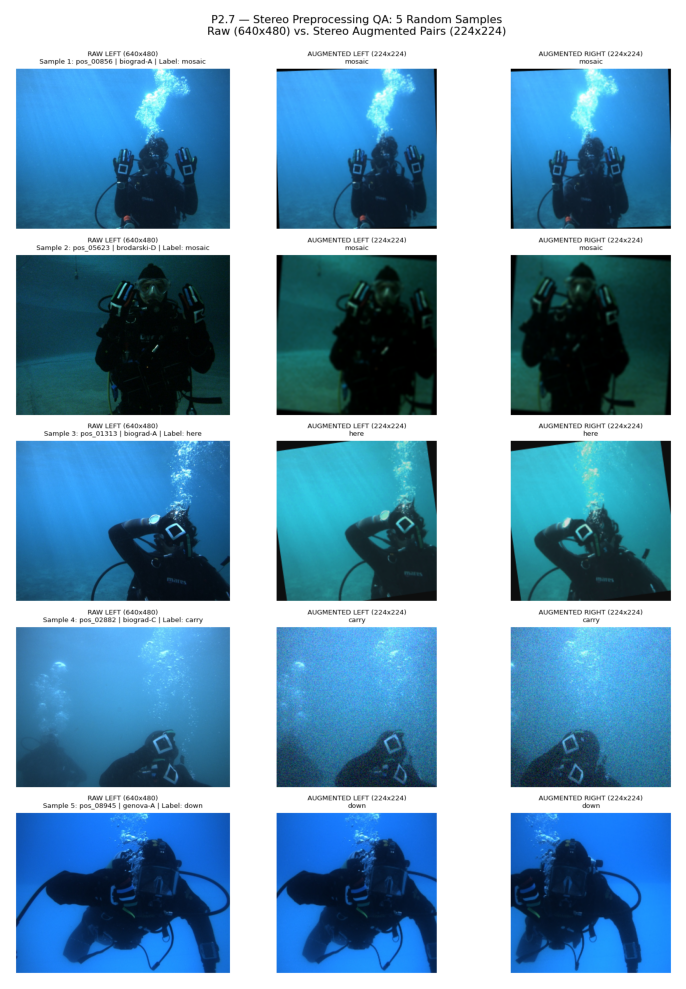

In [2]:
fig, ax = plt.subplots(figsize=(12, 10))
img1 = mpimg.imread(str(PROCESSED_DIR / 'preprocessing_raw_vs_augmented.png'))
ax.imshow(img1)
ax.axis('off')
plt.tight_layout()
plt.show()


## 2. Pixel Intensity Distributions (Raw vs Standardized Tensors)

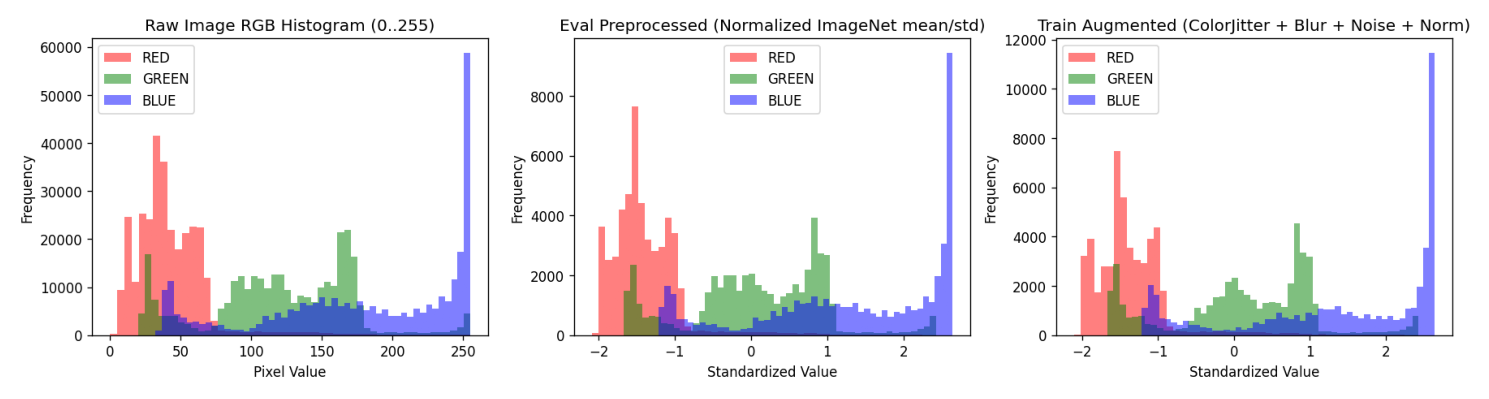

In [3]:
fig, ax = plt.subplots(figsize=(15, 5))
img2 = mpimg.imread(str(PROCESSED_DIR / 'preprocessing_rgb_histograms.png'))
ax.imshow(img2)
ax.axis('off')
plt.tight_layout()
plt.show()


## 3. Enhancement QA — Raw vs. FUnIE-GAN vs. WaterNet (Phase 3 / P3.6)

Compares the three cached image variants across all 8 scenarios.  
Also computes quantitative image statistics (mean brightness, contrast = pixel std,
and histogram shape) and flags any enhanced image whose histogram std falls below
20% of its raw counterpart as a **possible degenerate GAN output**.

> **Prerequisite:** Run `python scripts/cache_enhanced_images.py` first to populate
> `data/processed/enhanced/{none,funie_gan,waternet}/`.


In [ ]:
# Phase 3 / P3.6 — Enhancement QA: imports and configuration
import os
import sys
import random
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd

PROJECT_ROOT = Path(r'C:\Users\Tamim Syeedur Rahman\All Codes\sense-project')
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import Paths

MANIFEST_PATH    = Path('data/processed/manifest.csv')
CADDY_ROOT       = Path(Paths.CADDY_ROOT)
ENHANCED_DIR     = Path(Paths.ENHANCED_CACHE_DIR)
METHODS          = ['none', 'funie_gan', 'waternet']
DEGENERATE_THR   = 0.20   # flag if enhanced histogram std < 20% of raw std
SAMPLE_PER_SCENARIO = 2   # images to visualise per scenario
RANDOM_SEED      = 42
random.seed(RANDOM_SEED)

df_manifest = pd.read_csv(MANIFEST_PATH)
print(f'Manifest loaded: {len(df_manifest)} samples, '
      f'{df_manifest["scenario"].nunique()} scenarios')

# Check which methods are cached
for m in METHODS:
    n = len(list((ENHANCED_DIR / m).glob('*_left.png'))) if (ENHANCED_DIR / m).exists() else 0
    print(f'  {m:20s}: {n} left-image files cached')


In [ ]:
# Helper functions for image loading and statistics

def load_rgb(path: Path) -> np.ndarray:
    img = cv2.imread(str(path))
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)


def image_stats(img: np.ndarray) -> dict:
    """Return mean brightness, contrast (pixel std), and per-channel histogram stds."""
    brightness = float(img.mean())
    contrast   = float(img.std())
    hist_stds  = []
    for c in range(3):
        hist, _ = np.histogram(img[:, :, c], bins=256, range=(0, 255))
        hist_std = float(np.std(hist.astype(float)))
        hist_stds.append(hist_std)
    mean_hist_std = float(np.mean(hist_stds))
    return {'brightness': brightness, 'contrast': contrast,
            'hist_std': mean_hist_std, 'hist_stds_per_ch': hist_stds}


def load_all_variants(sample_id: str, side: str, left_path: str) -> dict:
    """Load raw and all enhanced variants for one sample side."""
    images = {}
    # Raw
    raw_p = CADDY_ROOT / left_path.lstrip('/')
    images['none'] = load_rgb(raw_p) if raw_p.exists() else None
    # Enhanced
    for m in ['funie_gan', 'waternet']:
        p = ENHANCED_DIR / m / f'{sample_id}_{side}.png'
        images[m] = load_rgb(p) if p.exists() else None
    return images

print('Helper functions defined.')


In [ ]:
# P3.6 — Visual comparison: 2 samples per scenario × 3 methods

scenarios = sorted(df_manifest['scenario'].unique())
print(f'Scenarios ({len(scenarios)}):', scenarios)

n_rows = len(scenarios) * SAMPLE_PER_SCENARIO
n_cols = len(METHODS)
fig, axes = plt.subplots(n_rows, n_cols,
                         figsize=(n_cols * 4, n_rows * 2.5),
                         squeeze=False)
fig.suptitle('Raw vs FUnIE-GAN vs WaterNet — left image, 2 samples per scenario',
             fontsize=13, fontweight='bold', y=1.01)

row = 0
missing_methods = set()
for scenario in scenarios:
    sc_df = df_manifest[df_manifest['scenario'] == scenario]
    samples = sc_df.sample(min(SAMPLE_PER_SCENARIO, len(sc_df)),
                          random_state=RANDOM_SEED)
    for _, r in samples.iterrows():
        variants = load_all_variants(r['sample_id'], 'left', r['left_path'])
        for col_i, method in enumerate(METHODS):
            ax = axes[row][col_i]
            img = variants.get(method)
            if img is not None:
                ax.imshow(img)
            else:
                ax.text(0.5, 0.5, f'{method}\nNOT CACHED',
                        ha='center', va='center', color='red', fontsize=8,
                        transform=ax.transAxes)
                ax.set_facecolor('#ffeaea')
                missing_methods.add(method)
            ax.axis('off')
            if row == 0:
                ax.set_title(method, fontsize=10, fontweight='bold')
            if col_i == 0:
                ax.set_ylabel(f'{scenario}\n{r["sample_id"]}',
                              fontsize=7, rotation=0, labelpad=70, va='center')
        row += 1

plt.tight_layout()
plt.savefig('data/processed/enhancement_qa_grid.png', dpi=120, bbox_inches='tight')
plt.show()
print(f'Grid saved → data/processed/enhancement_qa_grid.png')
if missing_methods:
    print(f'WARNING: methods not yet cached: {missing_methods}')
    print('Run: python scripts/cache_enhanced_images.py')


In [ ]:
# P3.6 — Quantitative statistics: brightness, contrast, histogram std
# Samples N images per (scenario × method) combination

N_STAT_SAMPLES = 20   # images per scenario × method
stats_rows = []

for scenario in scenarios:
    sc_df = df_manifest[df_manifest['scenario'] == scenario]
    sample_df = sc_df.sample(min(N_STAT_SAMPLES, len(sc_df)), random_state=RANDOM_SEED)
    for _, r in sample_df.iterrows():
        variants = load_all_variants(r['sample_id'], 'left', r['left_path'])
        for method in METHODS:
            img = variants.get(method)
            if img is None:
                continue
            s = image_stats(img)
            stats_rows.append({
                'scenario': scenario,
                'sample_id': r['sample_id'],
                'method': method,
                **s,
            })

stats_df = pd.DataFrame(stats_rows)
summary = stats_df.groupby('method')[['brightness', 'contrast', 'hist_std']].mean().round(2)
print('Mean statistics per enhancement method:')
print(summary.to_string())


In [ ]:
# P3.6 — Bar charts: mean brightness and contrast per scenario × method

if not stats_df.empty:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = {'none': '#5588cc', 'funie_gan': '#ee7733', 'waternet': '#44aa66'}

    for ax_i, metric in enumerate(['brightness', 'contrast']):
        ax = axes[ax_i]
        pivot = stats_df.groupby(['scenario', 'method'])[metric].mean().unstack('method')
        pivot[METHODS].plot(kind='bar', ax=ax,
                           color=[colors[m] for m in METHODS],
                           alpha=0.85, edgecolor='white')
        ax.set_title(f'Mean {metric.capitalize()} by Scenario', fontweight='bold')
        ax.set_xlabel('Scenario')
        ax.set_ylabel(metric.capitalize())
        ax.tick_params(axis='x', rotation=30)
        ax.legend(title='Method')
        ax.grid(axis='y', alpha=0.4)

    plt.tight_layout()
    plt.savefig('data/processed/enhancement_qa_stats.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('Stats chart saved → data/processed/enhancement_qa_stats.png')


In [ ]:
# P3.6 — Pixel histogram comparison for one random sample across all 3 methods

sample_row = df_manifest.sample(1, random_state=RANDOM_SEED).iloc[0]
variants_hist = load_all_variants(sample_row['sample_id'], 'left', sample_row['left_path'])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ch_colors = ['red', 'green', 'blue']

for col_i, method in enumerate(METHODS):
    ax = axes[col_i]
    img = variants_hist.get(method)
    if img is None:
        ax.text(0.5, 0.5, f'{method}\nNOT CACHED', ha='center', va='center',
                color='red', transform=ax.transAxes)
        ax.set_title(method)
        continue
    for ch, color in enumerate(ch_colors):
        hist, edges = np.histogram(img[:, :, ch], bins=128, range=(0, 255))
        ax.plot(edges[:-1], hist, color=color, alpha=0.7, linewidth=1.2)
    ax.set_title(f'{method}', fontweight='bold')
    ax.set_xlabel('Pixel value')
    ax.set_ylabel('Count')
    ax.grid(alpha=0.35)

fig.suptitle(
    f'Histogram comparison — {sample_row["sample_id"]} '
    f'(scenario: {sample_row["scenario"]})',
    fontweight='bold'
)
plt.tight_layout()
plt.savefig('data/processed/enhancement_qa_histogram.png', dpi=120, bbox_inches='tight')
plt.show()
print('Histogram saved → data/processed/enhancement_qa_histogram.png')


In [ ]:
# P3.6 — Degenerate GAN output detection
# Flag enhanced images whose histogram std < 20% of their raw counterpart.

print(f'Degenerate output threshold: enhanced hist_std < {DEGENERATE_THR:.0%} of raw hist_std')
print(f'Scanning {N_STAT_SAMPLES} samples per scenario ({len(scenarios)} scenarios) ...')

degenerate_flags = []

for scenario in scenarios:
    sc_df = df_manifest[df_manifest['scenario'] == scenario]
    sample_df = sc_df.sample(min(N_STAT_SAMPLES, len(sc_df)), random_state=RANDOM_SEED)
    for _, r in sample_df.iterrows():
        variants = load_all_variants(r['sample_id'], 'left', r['left_path'])
        raw_img = variants.get('none')
        if raw_img is None:
            continue
        raw_stats = image_stats(raw_img)
        for method in ['funie_gan', 'waternet']:
            enh_img = variants.get(method)
            if enh_img is None:
                continue
            enh_stats = image_stats(enh_img)
            ratio = (enh_stats['hist_std'] / raw_stats['hist_std']
                     if raw_stats['hist_std'] > 0 else 1.0)
            if ratio < DEGENERATE_THR:
                degenerate_flags.append({
                    'sample_id': r['sample_id'],
                    'scenario': scenario,
                    'method': method,
                    'raw_hist_std': round(raw_stats['hist_std'], 2),
                    'enh_hist_std': round(enh_stats['hist_std'], 2),
                    'ratio': round(ratio, 4),
                })

if degenerate_flags:
    flags_df = pd.DataFrame(degenerate_flags)
    print(f'\n⚠  {len(flags_df)} DEGENERATE outputs flagged:')
    print(flags_df.to_string(index=False))
else:
    print(f'\n✅ No degenerate GAN outputs detected in the sampled set.')
    print('   (If weights are missing, all enhanced images are absent — '
          'run cache_enhanced_images.py first.)')


### Phase 3 / P3.6 QA Summary

| Check | Result |
|-------|--------|
| Visual grid (raw vs FUnIE-GAN vs WaterNet, 8 scenarios × 2 samples) | see grid above |
| Quantitative stats (brightness / contrast / histogram std per method) | see bar charts |
| Histogram shape comparison (1 sample) | see histogram above |
| Degenerate output detection (hist_std < 20% of raw) | see cell above |

> **Saved artefacts:**  
> `data/processed/enhancement_qa_grid.png`  
> `data/processed/enhancement_qa_stats.png`  
> `data/processed/enhancement_qa_histogram.png`

See also `data/processed/enhancement_report.md` for the full
completeness / stereo-integrity verification report from P3.5.
